*  DSC630-T303 Predictive Analytics (2267-1)
*  1.2 Assignment: R/Python Refresher
*  David Jorgensen

# 1.2 Assignment: R/Python Refresher

# Instructions

This assignment is a refresher on data analysis and visualization using Python and/or R. With the dataset `data/sports_fan_survey_2024.csv` (explanation of data found in `data/data_dictionary.csv`), perform the following steps using Python:

- Write a summary of your data and identify at least two questions to explore visually with your data.
- Create a histogram or bar graph from your data.
- Create a boxplot from your data.
- Create a bivariate plot from your data.
- Create any additional visualizations that will help to answer the question(s) you want to answer.
- Summarize your results and make a conclusion.

# Assignment

In [11]:
# Widen the notebook so code and outputs do not get cut off in the PDF export.
from IPython.display import display, HTML
display(HTML("<style>.container { width:100% !important; }</style>"))

## 1. Load the data and required libraries

I use **pandas** for data handling and **matplotlib / seaborn** for visualization. The survey lives under the `data/` folder (inside the extracted Kaggle `archive` directory).

In [12]:
# Core data + plotting libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Consistent, readable plot styling
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.titlesize"] = 13

# Load the Global Sports Fan Survey 2024 (2,200 respondents, 42 columns)
df = pd.read_csv("data/sports_fan_survey_2024.csv")

# Quick look at shape and the first few rows
print("Rows, Columns:", df.shape)
df.head()

Rows, Columns: (2200, 42)


,respondent_id,survey_year,survey_month,survey_platform,response_time_minutes,country,region,age,gender,education_level,...,willing_to_attend_major_event,extra_spend_willingness_usd,broadcast_quality_rating,athlete_professionalism_rating,event_value_for_money_rating,media_coverage_rating,community_atmosphere_rating,overall_satisfaction_rating,sport_growth_perception_rating,fan_tier
0,1,2024,8,In-app,16,Brazil,South America,59,Female,Bachelor's degree,...,Maybe,17.82,5,9,1,8,5,10,1,Silver
1,2,2024,12,Online (desktop),14,China,East Asia,42,Male,Doctorate,...,Definitely yes,7.26,10,7,8,8,7,7,10,Silver
2,3,2024,10,Online (desktop),13,Canada,North America,46,Female,Master's degree,...,Probably yes,19.59,6,8,5,8,9,7,10,Bronze
3,4,2024,2,Online (mobile),11,Australia,Oceania,27,Male,Master's degree,...,Probably not,8.44,5,9,5,7,10,7,9,Gold
4,5,2024,10,In-app,6,USA,North America,22,Male,High school,...,Definitely yes,17.80,7,7,5,4,9,9,6,Bronze


## 2. Data summary

Below I inspect the column types, basic descriptive statistics for the numeric fields, and the amount of missing data.

In [13]:
# Column names, data types, and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 42 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   respondent_id                   2200 non-null   int64  
 1   survey_year                     2200 non-null   int64  
 2   survey_month                    2200 non-null   int64  
 3   survey_platform                 2200 non-null   object 
 4   response_time_minutes           2200 non-null   int64  
 5   country                         2200 non-null   object 
 6   region                          2200 non-null   object 
 7   age                             2200 non-null   int64  
 8   gender                          2200 non-null   object 
 9   education_level                 2200 non-null   object 
 10  employment_status               2200 non-null   object 
 11  income_bracket                  2200 non-null   object 
 12  primary_sport                   22

In [14]:
# Descriptive statistics for a focused set of numeric columns of interest
cols = [
    "age", "years_following_sport", "fan_loyalty_score",
    "weekly_hours_watching", "merchandise_spend_usd",
    "total_annual_spend_usd", "overall_satisfaction_rating",
]
df[cols].describe().round(2)

,age,years_following_sport,fan_loyalty_score,weekly_hours_watching,merchandise_spend_usd,total_annual_spend_usd,overall_satisfaction_rating
count,2200.00,2200.00,2200.00,2200.00,2200.0,2200.00,2200.00
mean,33.18,13.38,3.34,6.89,56.6,90.70,7.49
std,10.41,8.72,1.42,4.65,84.7,105.61,1.45
min,18.00,1.00,1.00,0.50,0.0,0.00,3.00
25%,25.00,7.00,2.00,3.10,9.0,27.00,7.00
50%,33.00,12.00,3.00,6.40,27.0,57.00,8.00
75%,41.00,18.00,4.00,9.70,69.0,114.00,9.00
max,65.00,57.00,8.00,26.10,921.0,1026.00,10.00


In [15]:
# Check for missing values
missing = df.isna().sum()
missing[missing > 0]

secondary_sport    968
dtype: int64

### Summary of the data

The **Global Sports Fan Survey 2024** is a synthetic but realistically calibrated dataset of **2,200 respondents** described by **42 columns**. Each row is one survey respondent. The columns group into:

- **Demographics**: `age` (18–65), `gender`, `country` (15 countries), `region`, `education_level`, `employment_status`, and `income_bracket`.
- **Sport preferences**: `primary_sport` (26 sports across 4 categories), `years_following_sport`, and a self-reported `fan_loyalty_score` (1–10).
- **Viewing & engagement**: `weekly_hours_watching`, `streaming_subscriptions`, `stadium_visits_per_year`, and social-media activity.
- **Spending**: `merchandise_spend_usd`, `ppv_spend_usd`, and their sum `total_annual_spend_usd`.
- **Attitude ratings** (1–10) and a composite engagement label, `fan_tier` (Bronze / Silver / Gold / Platinum).

The only missing data is in `secondary_sport` (~44% of fans selected no second sport), which is expected and does not affect this analysis. Descriptive statistics show that spending is **right-skewed**, where the median `total_annual_spend_usd` is far below the mean because a small group of super-fans spends heavily.

### Two questions to explore visually

1. **Does household income drive how much fans spend on their sport?** (i.e., does `total_annual_spend_usd` rise across `income_bracket`?)
2. **Is a fan's loyalty tied to how long they have followed the sport, and does higher loyalty translate into more merchandise spending?** (relationship among `years_following_sport`, `fan_loyalty_score`, and `merchandise_spend_usd`).

## 3. Histogram: distribution of total annual spend

Before comparing groups, I look at the overall shape of `total_annual_spend_usd`. This tells me whether spending is symmetric or skewed, which guides how I interpret later group comparisons.

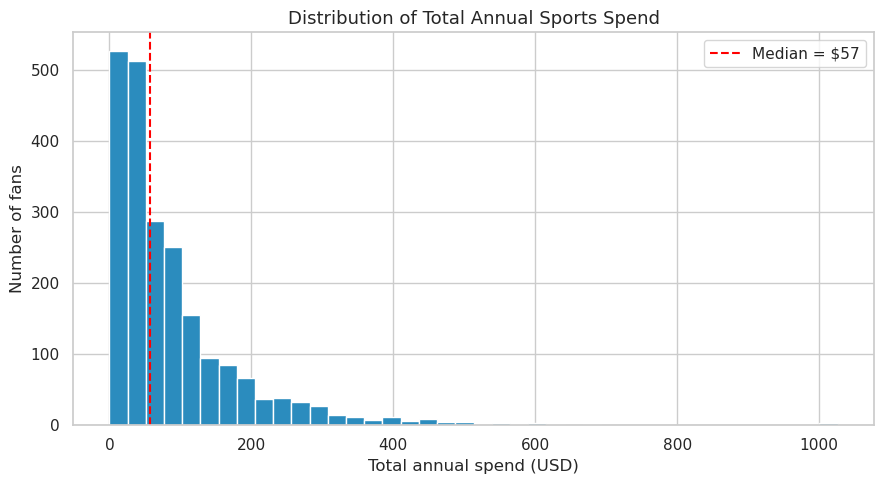

In [16]:
# Histogram of total annual spend with the median marked
fig, ax = plt.subplots()
ax.hist(df["total_annual_spend_usd"], bins=40, color="#2b8cbe", edgecolor="white")
median_spend = df["total_annual_spend_usd"].median()
ax.axvline(median_spend, color="red", linestyle="--",
           label=f"Median = ${median_spend:,.0f}")
ax.set_title("Distribution of Total Annual Sports Spend")
ax.set_xlabel("Total annual spend (USD)")
ax.set_ylabel("Number of fans")
ax.legend()
plt.tight_layout()
plt.show()

**Interpretation:** Spending is strongly **right-skewed**. The large majority of fans spend a modest amount each year (the median is only a few tens of dollars), while a long tail of fans spends hundreds of dollars. This skew is why I use **medians and boxplots** rather than means when comparing groups below, since a handful of big spenders would otherwise distort the averages.

## 4. Boxplot: spend by income bracket (Question 1)

To answer **Question 1**, I compare `total_annual_spend_usd` across the ordered `income_bracket` categories. A boxplot is ideal here because it shows the median, spread, and outliers for each group despite the skew seen above.

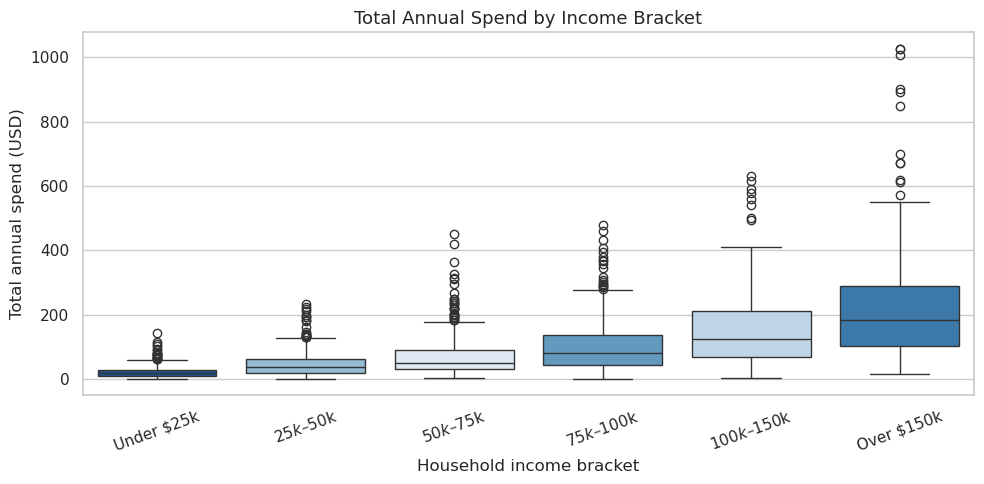

income_bracket
Under $25k      17.0
$25k–$50k       37.0
$50k–$75k       50.5
$75k–$100k      80.5
$100k–$150k    123.0
Over $150k     182.0
Name: total_annual_spend_usd, dtype: float64

In [17]:
# Define the natural order of income brackets so the x-axis reads low -> high
income_order = [
    "Under $25k", "$25k–$50k", "$50k–$75k",
    "$75k–$100k", "$100k–$150k", "Over $150k",
]

fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(
    data=df, x="income_bracket", y="total_annual_spend_usd",
    order=income_order, hue="income_bracket", palette="Blues",
    legend=False, ax=ax,
)
ax.set_title("Total Annual Spend by Income Bracket")
ax.set_xlabel("Household income bracket")
ax.set_ylabel("Total annual spend (USD)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# Median spend per bracket to back up the visual
df.groupby("income_bracket")["total_annual_spend_usd"].median().reindex(income_order)

**Interpretation:** Both the boxes and the median table show a clear upward trend, where median spending rises steadily from the Under $25k group to the Over $150k group, and the higher brackets also have taller boxes and higher outliers. This supports the idea that household income is a real driver of sports spending: wealthier fans not only spend more on average, they also have a wider ceiling on what they are willing to spend.

## 5. Bivariate plot: loyalty vs. years following the sport (Question 2)

To begin answering Question 2, I plot `fan_loyalty_score` against `years_following_sport`. Because both variables are discrete integers, a raw scatter would overplot, so I add a small amount of jitter and a regression line to reveal the trend.

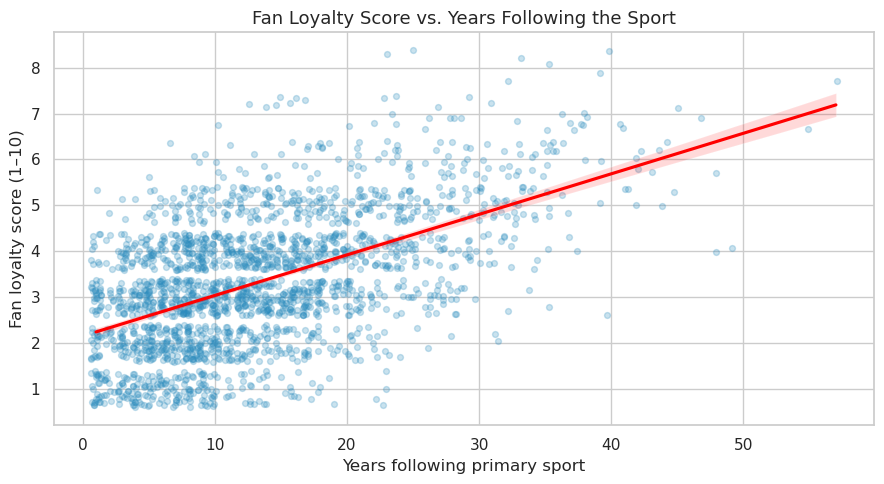

Correlation (years following vs. loyalty): 0.54


In [18]:
# Jittered scatter with regression line
fig, ax = plt.subplots()
sns.regplot(
    data=df, x="years_following_sport", y="fan_loyalty_score",
    scatter_kws={"alpha": 0.25, "s": 18, "color": "#2b8cbe"},
    line_kws={"color": "red"}, x_jitter=0.4, y_jitter=0.4, ax=ax,
)
ax.set_title("Fan Loyalty Score vs. Years Following the Sport")
ax.set_xlabel("Years following primary sport")
ax.set_ylabel("Fan loyalty score (1–10)")
plt.tight_layout()
plt.show()

# Correlation coefficient
corr = df["years_following_sport"].corr(df["fan_loyalty_score"])
print(f"Correlation (years following vs. loyalty): {corr:.2f}")

**Interpretation:** The regression line slopes clearly upward and the correlation of about 0.54 indicates a moderate positive relationship: the longer someone has followed their sport, the higher their self-reported loyalty tends to be. Loyalty appears to be earned over time rather than instant.

## 6. Additional visualizations

Question 2 also asks whether loyalty translates into spending. I first bin `fan_loyalty_score` into Low / Medium / High and compare median merchandise spend, then show a correlation heatmap to summarize all the numeric relationships at once.

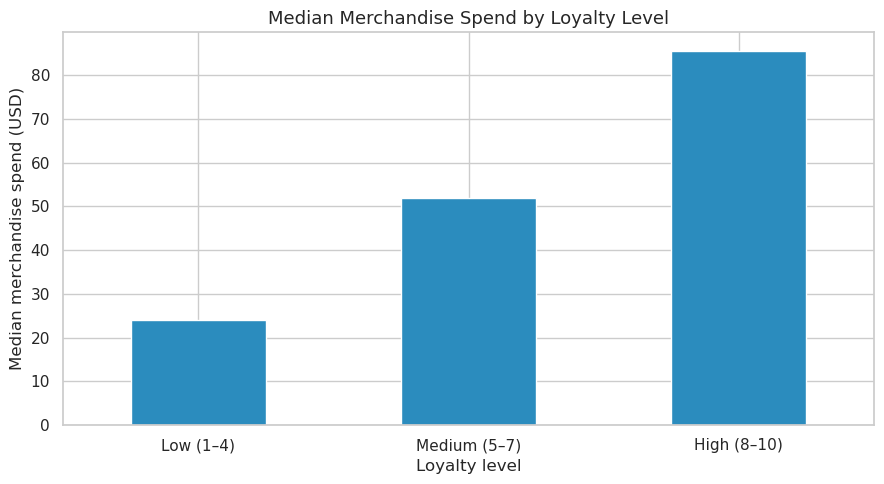

loyalty_level
Low (1–4)       24.0
Medium (5–7)    52.0
High (8–10)     85.5
Name: merchandise_spend_usd, dtype: float64

In [19]:
# Bin loyalty into three readable levels
df["loyalty_level"] = pd.cut(
    df["fan_loyalty_score"], bins=[0, 4, 7, 10],
    labels=["Low (1–4)", "Medium (5–7)", "High (8–10)"],
)

# Median merchandise spend per loyalty level
spend_by_loyalty = (
    df.groupby("loyalty_level", observed=True)["merchandise_spend_usd"].median()
)

fig, ax = plt.subplots()
spend_by_loyalty.plot(kind="bar", color="#2b8cbe", edgecolor="white", ax=ax)
ax.set_title("Median Merchandise Spend by Loyalty Level")
ax.set_xlabel("Loyalty level")
ax.set_ylabel("Median merchandise spend (USD)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

spend_by_loyalty

**Interpretation:** Median merchandise spend rises with loyalty level; highly loyal fans spend noticeably more on merchandise than casual fans. Combined with the previous plot, this completes the story for Question 2: years following → higher loyalty → more merchandise spend.

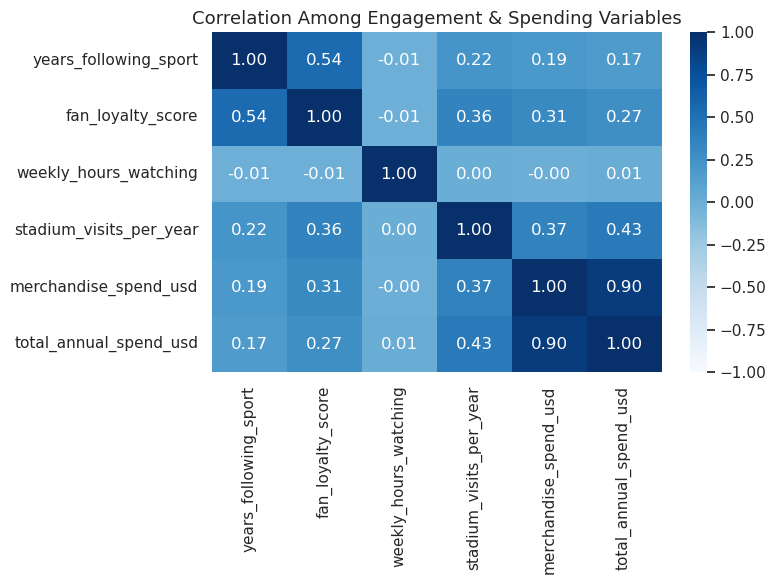

In [20]:
# Correlation heatmap of the key numeric engagement / spending variables
heat_cols = [
    "years_following_sport", "fan_loyalty_score",
    "weekly_hours_watching", "stadium_visits_per_year",
    "merchandise_spend_usd", "total_annual_spend_usd",
]
corr_matrix = df[heat_cols].corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="Blues",
            vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation Among Engagement & Spending Variables")
plt.tight_layout()
plt.show()

**Interpretation:** The heatmap supports the patterns above. The strongest positive cell is `years_following_sport` ↔ `fan_loyalty_score` (~0.54), and `fan_loyalty_score` ↔ `merchandise_spend_usd` is also positive (~0.31). Note that `weekly_hours_watching` is essentially **uncorrelated** with loyalty and spend: watching more does not necessarily mean spending more.

## 7. Conclusion

**Question 1: Does income drive spending?** Yes. The boxplot of `total_annual_spend_usd` across the ordered income brackets showed a steady rise in both the median and the upper spread of spending as income increased. Because the histogram revealed that spending is heavily right-skewed, I relied on medians rather than means, and the medians still climbed cleanly from the lowest to the highest income bracket. I conclude that **household income is a genuine driver of how much fans spend on their sport.**

**Question 2: Is loyalty tied to tenure and to spending?** Also yes. The bivariate regression plot showed a clear upward relationship between years following the sport and loyalty (correlation ≈ 0.54), and the loyalty-level bar chart showed that median merchandise spend rises from low- to high-loyalty fans. The correlation heatmap tied these together and added the useful caveat that *time spent watching* is not correlated with loyalty or spend. I conclude that **loyalty is built over years of following a sport, and more loyal fans convert that loyalty into higher merchandise spending.**

**How the visualizations support the conclusions:** 
- The **histogram** put the median spend line at only **\$57** against a tail reaching past **\$1,000**, diagnosing the right skew that justified median-based comparisons. 
- The **boxplot**'s median table then climbed monotonically across income brackets. **\$17** (Under \$25k) → **\$37** → **\$50.50** → **\$80.50** → **\$123** → **\$182** (Over \$150k). This result strongly supports the income effect. 
- The **bivariate regression plot** printed a correlation of **0.54** between years following and loyalty, exposing the tenure → loyalty trend. 
- The **bar chart** showed median merchandise spend rising **\$24 → \$52 → \$85.50** from Low to High loyalty.
- The **heatmap** summarized it all: the strongest cell `years_following_sport` ↔ `fan_loyalty_score` at **~0.54**, `fan_loyalty_score` ↔ `merchandise_spend_usd` at **~0.31**, and `weekly_hours_watching` near zero against both.